# Descriptive analysis of Chicago restaurants and reviews

This notebook analyzes the two cleaned CSVs in this folder. Run all cells from top to bottom. It displays tables and charts inline and also saves the original report, tables, and figures in `analysis_outputs/`.

- **Restaurants:** one row per accepted restaurant, with Google metadata and inspection-history summaries.
- **Reviews:** one deduplicated review per row; `restaurant_id` links reviews to restaurants.

See `dataset_description.txt` for sources, collection details, all column definitions, benefits, and limitations.

## Data preparation already performed

The preparation pipeline selected Chicago restaurants; removed identical metadata and review records; accepted only exact name/address/unit/ZIP links with stable histories and coordinates within 25 meters; and parsed UTC and Chicago-local dates. It preserved missing values and date/conflict flags.

Ratings without text remain useful for rating analysis. Flagged dates are retained for audit but excluded from date-based analysis. The optional primary monthly subset requires a unique scored inspection strictly before the review month, at most 365 days old. Inspection-history summaries cover more years than the reviews and must not be treated as contemporaneous predictors.

## Methods from the course repositories

The analysis follows `datamining/module2/[6] Introduction to EDA (Complete).ipynb`: missingness/info (cells 10?11), describe (27), histograms/boxplots (32/34), frequency tables (41/44), scatterplots (55), grouped summaries (58), crosstabs (62), and correlations (64).

It also uses the missing-count/fraction and numeric-summary methods in `ISA591/Class Notebooks/[7] ISA591 EDA Worksheet Part2 (Complete).ipynb` (cells 6?7, 11, 23, 39). Cell numbers are zero-based notebook indices. These are descriptive methods; no predictive model is fitted.

## Imports and data-loading helpers

In [1]:
import io
import json
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BOOL_COLUMNS = ['has_text','date_valid_for_analysis','rating_valid','user_id_present','identity_conflict',
                'eligible_for_monthly_candidate','included_in_primary_month']
INSPECTION_RESULTS = {
    'Pass':'inspection_pass_count','Pass w/ Conditions':'inspection_conditional_count','Fail':'inspection_fail_count',
    'No Entry':'inspection_no_entry_count','Not Ready':'inspection_not_ready_count',
    'Out of Business':'inspection_out_of_business_count','Business Not Located':'inspection_business_not_located_count',
}
from IPython.display import display, Markdown

ANALYSIS_INTRO = 'Descriptive analysis of the cleaned Chicago restaurant and review datasets.\n\nOpen descriptive_analysis.ipynb and run all cells from top to bottom.\n\nDataset introduction\n--------------------\ncleaned_restaurants.csv has one row per accepted Google/Chicago-inspection\nrestaurant. reviews.csv has one row per deduplicated review for those restaurants.\nInspection histories are aggregated at restaurant level; reviews remain separate\nto prevent reviews-times-inspections joins. restaurant_id links the two tables.\n\nPreparation already performed by build_initial_merge.py / prepare_final_data.py:\nChicago/restaurant filtering; identical metadata/review deduplication; exact\nnames/address/unit/ZIP matching with stable histories and <=25m coordinates;\nUTC and Chicago-local date parsing; explicit missingness/conflict/date flags;\ntemporal checks for the optional prior-inspection subset; and one-to-one or\nmany-to-one validated merges. Flagged timestamps remain available for audit.\nRatings without text are retained. We do not fill unknown values with zeros.\n\nCourse methods used (zero-based notebook cell indices):\n* datamining/module2/[6] Introduction to EDA (Complete).ipynb:\n  10-11 isna/info, 27 describe, 32/34 hist/boxplot, 41/44 value_counts,\n  55 scatterplot, 58 groupby/agg, 62 crosstab, 64 correlation.\n* ISA591/Class Notebooks/[7] ISA591 EDA Worksheet Part2 (Complete).ipynb:\n  6-7, 11, 23, 39: missing counts/fractions, mean/median and numeric summaries.\n\nThis notebook uses only pandas, numpy, Matplotlib, and the Python standard library.\nIt writes reproducible tables, figures, and descriptive_analysis_report.txt into\nanalysis_outputs/. It fits no predictive model and makes no causal claims.'

Cannot install event loop hook for "qt" when running with `--simple-prompt`.
NOTE: Tk is supported natively; use Tk apps and Tk backends with `--simple-prompt`.
No event loop hook running.


In [2]:
def load_data(directory):
    # Load all columns as strings first so IDs/ZIPs never become floating point.
    # Literal review text such as "NA" is preserved; only empty fields are missing.
    restaurants=pd.read_csv(directory/'cleaned_restaurants.csv',dtype='string',keep_default_na=False).replace('',pd.NA)
    reviews=pd.read_csv(directory/'reviews.csv',dtype='string',keep_default_na=False).replace('',pd.NA)
    restaurant_numeric=[c for c in restaurants if c.endswith('_count') or c.startswith('snapshot_') or c in
        ['latitude','longitude','match_distance_max_m','inspection_failure_share','reviews_with_text','mean_export_rating','median_export_rating']]
    for c in restaurant_numeric: restaurants[c]=pd.to_numeric(restaurants[c],errors='raise')
    for c in ['rating','time_ms','review_year','prior_inspection_age_days']:
        reviews[c]=pd.to_numeric(reviews[c],errors='raise')
    for c in BOOL_COLUMNS:
        assert reviews[c].isin(['True','False']).all(),f'Unexpected boolean: {c}'
        reviews[c]=reviews[c].map({'True':True,'False':False}).astype('boolean')
    for c in restaurants.columns:
        if c.endswith('_date'): restaurants[c]=pd.to_datetime(restaurants[c],errors='raise')
    for c in ['review_date_chicago','review_month','prior_inspection_date']:
        reviews[c]=pd.to_datetime(reviews[c],errors='raise')
    # ISO timestamps may have zero or three fractional-second digits.
    reviews['review_time_utc']=pd.to_datetime(reviews['review_time_utc'],format='ISO8601',utc=True,errors='raise')
    reviews.loc[reviews['text'].fillna('').str.strip().eq(''),'text']=pd.NA
    return restaurants,reviews

## Validation and summary helpers

These checks protect the table keys, restaurant/review relationships, eligibility flags, and strictly prior inspection links.

In [3]:
def validate(restaurants,reviews):
    assert restaurants['restaurant_id'].is_unique and reviews['review_id'].is_unique
    assert restaurants['gmap_id'].is_unique
    assert set(reviews['restaurant_id'])==set(restaurants['restaurant_id'])
    assert restaurants['city'].eq('CHICAGO').all() and restaurants['geographic_state'].eq('IL').all()
    mapped=reviews[['restaurant_id','gmap_id']].merge(restaurants[['restaurant_id','gmap_id']],on='restaurant_id',validate='many_to_one',suffixes=('_review','_restaurant'))
    assert mapped['gmap_id_review'].eq(mapped['gmap_id_restaurant']).all()
    count=reviews.groupby('restaurant_id').size().sort_index()
    assert count.eq(restaurants.set_index('restaurant_id')['review_count'].sort_index()).all()
    assert restaurants[list(INSPECTION_RESULTS.values())].sum(axis=1).eq(restaurants['inspection_count']).all()
    assert reviews['date_valid_for_analysis'].eq(reviews['date_status'].eq('valid')).all()
    assert reviews['has_text'].eq(reviews['text'].fillna('').str.strip().ne('')).all()
    assert reviews['rating_valid'].all() and reviews['rating'].between(1,5).all()
    assert not reviews['identity_conflict'].any()
    included=reviews.loc[reviews['included_in_primary_month']]
    assert included['prior_inspection_date'].lt(included['review_month']).all()
    assert included['prior_inspection_age_days'].between(1,365).all()
    assert included['date_valid_for_analysis'].all()
    assert included['prior_inspection_result'].isin(['Pass','Pass w/ Conditions','Fail']).all()
    assert reviews.loc[~reviews['included_in_primary_month'],'prior_inspection_id'].isna().all()
    assert len(included)==restaurants['primary_month_review_count'].sum()

def missing_table(frame):
    # Same missing-count and fraction method as ISA591 EDA Part2, cell 11.
    return pd.DataFrame({'missing_count':frame.isna().sum(),'missing_fraction':frame.isna().mean(),
                         'dtype':frame.dtypes.astype(str)}).sort_values('missing_fraction',ascending=False)

def date_range(series):
    return [series.min().date().isoformat(),series.max().date().isoformat()] if series.notna().any() else [None,None]

## Locate the files and load the data

The path check supports launching from this folder, the repository, or the GitHub workspace. Identifiers and ZIP codes are read as strings. Empty fields remain missing; literal text such as `NA` is preserved.

In [4]:
candidates = []
for base in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([base, base / "data" / "final data", base / "ChicagoPizza514" / "data" / "final data"])
directory = next((p for p in candidates if (p / "cleaned_restaurants.csv").is_file() and (p / "reviews.csv").is_file()), None)
if directory is None:
    raise FileNotFoundError("Cannot locate cleaned_restaurants.csv and reviews.csv; set directory to their folder.")
print("Data folder:", directory)

output=directory/'analysis_outputs'
output.mkdir(parents=True,exist_ok=True)
restaurants,reviews=load_data(directory)
validate(restaurants,reviews)
# Explicitly separate date-independent ratings from eligible date analysis.
rated=reviews.loc[reviews['rating_valid']].copy()
dated=rated.loc[rated['date_valid_for_analysis']].copy()
dated['year']=dated['review_date_chicago'].dt.year
textual=rated.loc[rated['has_text']].copy()
textual['text_character_count']=textual['text'].str.len()
primary=reviews.loc[reviews['included_in_primary_month']]

print(f"Restaurants: {len(restaurants):,}; reviews: {len(reviews):,}")
print("Validation passed.")
display(restaurants[["restaurant_id", "place_name", "review_count", "inspection_count"]].head())

Data folder: C:\Users\mctigufb\Documents\GitHub\ChicagoPizza514\data\final data
Restaurants: 252; reviews: 125,254
Validation passed.


,restaurant_id,place_name,review_count,inspection_count
0,google:0x880e2fd6c1f745c3:0x90ee16b80773296d,4 Seasons,18,13
1,google:0x880e2cc2c31b04fd:0xcb8a5ae37574cd33,9 Muses Bar & Grill,291,20
2,google:0x880e2fee899c0795:0xe6eae9a54168692c,A P Deli & Grill Viii,124,19
3,google:0x880fd3a7e55ecacb:0x9a525f4fe5188ea8,Aje Cafe,157,15
4,google:0x880fd1887e654691:0xda6183e549f7cc38,Andies Restaurant,384,32


## Descriptive statistics

Date-independent rating statistics use valid ratings. Annual summaries use valid Chicago-local dates. The primary subset additionally applies inspection timing rules. These denominators are kept separate.

In [5]:
restaurant_summary=restaurants.select_dtypes(include='number').describe().T
review_summary=rated[['rating']].describe().T
text_summary=textual[['text_character_count']].describe().T
restaurant_missing=missing_table(restaurants)
review_missing=missing_table(reviews)
rating_counts=rated['rating'].value_counts().sort_index().rename('review_count').to_frame()
rating_counts['share']=rating_counts['review_count']/len(rated)
yearly=dated.groupby('year').agg(review_count=('review_id','size'),restaurant_count=('restaurant_id','nunique'),
                               mean_rating=('rating','mean'),median_rating=('rating','median'),text_count=('has_text','sum'))
primary_status=reviews['primary_analysis_status'].value_counts(dropna=False).rename('review_count').to_frame()
inspection_counts=pd.Series({label:int(restaurants[col].sum()) for label,col in INSPECTION_RESULTS.items()},name='event_count').to_frame()
inspection_counts['share_of_all_events']=inspection_counts['event_count']/restaurants['inspection_count'].sum()
# Course crosstab method: categorical rating levels versus text availability.
text_by_rating=pd.crosstab(rated['rating'],rated['has_text'],normalize='index').rename(columns={False:'without_text_share',True:'with_text_share'})
categories=restaurants['categories_json'].dropna().map(json.loads).explode().value_counts().rename('restaurant_count').to_frame()
# These correlations use review-era summaries only, not later inspection outcomes.
review_features=restaurants[['review_count','mean_export_rating']].copy()
review_features['text_share']=restaurants['reviews_with_text']/restaurants['review_count']
correlations=review_features.corr()

display(restaurant_summary)
display(review_summary)
display(text_summary)

,count,mean,std,min,25%,50%,75%,max
latitude,252.0,41.887784,0.074229,41.648652,41.847999,41.901834,41.941669,42.010368
longitude,252.0,-87.672794,0.049748,-87.83407,-87.697556,-87.66937,-87.644761,-87.525929
snapshot_avg_rating,252.0,4.244444,0.376301,1.5,4.1,4.3,4.5,4.9
snapshot_num_reviews,252.0,502.22619,600.537509,2.0,138.0,327.0,626.0,5529.0
match_distance_max_m,252.0,11.704561,5.944593,0.064682,6.873757,11.272384,16.010499,24.744255
inspection_count,252.0,21.202381,7.806596,3.0,16.0,22.0,25.0,60.0
inspection_pass_count,252.0,11.734127,4.85289,1.0,8.0,12.0,15.0,34.0
inspection_conditional_count,252.0,3.777778,2.39983,0.0,2.0,3.0,5.0,12.0
inspection_fail_count,252.0,4.011905,3.377311,0.0,2.0,3.0,6.0,24.0
inspection_no_entry_count,252.0,1.384921,2.835224,0.0,0.0,0.0,1.0,15.0


,count,mean,std,min,25%,50%,75%,max
rating,125254.0,4.270674,1.144814,1.0,4.0,5.0,5.0,5.0


,count,mean,std,min,25%,50%,75%,max
text_character_count,68144.0,128.856568,187.892728,1.0,31.0,69.0,152.0,6912.0


## Missingness

Missing `prior_inspection_*` values are structural for records outside the primary monthly subset. Blank unit fields mean no unit was supplied. A parseable pre-2010 date can remain excluded because it predates inspection coverage.

In [6]:
display(restaurant_missing.loc[restaurant_missing["missing_count"].gt(0)])
display(review_missing.loc[review_missing["missing_count"].gt(0)])

,missing_count,missing_fraction,dtype
unit,252,1.000000,string
operating_status,87,0.345238,string
business_description,53,0.210317,string
price,21,0.083333,string
hours_json,8,0.031746,string


,missing_count,missing_fraction,dtype
text,57110,0.455954,string
prior_inspection_result,22205,0.177280,string
prior_inspection_date,22205,0.177280,datetime64[ns]
prior_inspection_id,22205,0.177280,string
prior_inspection_age_days,22205,0.177280,Int64
review_year,44,0.000351,Int64


## Frequencies, coverage, and categorical relationships

Categories overlap. Inspection outcomes count events, not restaurants. Text availability is summarized within each rating level.

In [7]:
display(rating_counts)
display(yearly)
display(inspection_counts)
display(primary_status)
display(text_by_rating)
display(categories.head(15))

,review_count,share
rating,,
1.0,7712,0.061571
2.0,4236,0.033819
3.0,10735,0.085706
4.0,26325,0.210173
5.0,76246,0.608731


,review_count,restaurant_count,mean_rating,median_rating,text_count
year,,,,,
2010,114,57,3.77193,4.0,45
2011,278,113,4.115108,4.0,108
2012,505,148,4.083168,4.0,390
2013,1623,176,4.171904,4.0,1389
2014,998,196,4.121242,5.0,775
2015,2039,218,4.019617,5.0,1439
2016,6479,226,4.143232,5.0,4047
2017,16893,230,4.250696,5.0,9509
2018,33488,237,4.288253,5.0,16895


,event_count,share_of_all_events
Pass,2957,0.553434
Pass w/ Conditions,952,0.178177
Fail,1011,0.189220
No Entry,349,0.065319
Not Ready,12,0.002246
Out of Business,62,0.011604
Business Not Located,0,0.000000


,review_count
primary_analysis_status,
included,103049
prior_inspection_older_than_365_days,17464
outside_observed_scored_inspection_span,2265
latest_prior_event_not_scored,2060
month_not_bracketed_by_scored_observations,227
latest_inspection_same_day_tie,145
before_analysis_coverage,44


has_text,without_text_share,with_text_share
rating,,
1.0,0.237811,0.762189
2.0,0.343248,0.656752
3.0,0.513274,0.486726
4.0,0.520988,0.479012
5.0,0.453755,0.546245


,restaurant_count
categories_json,
Restaurant,99
Sandwich shop,42
Fast food restaurant,40
Mexican restaurant,37
American restaurant,32
Takeout Restaurant,30
Caterer,29
Pizza restaurant,28
Bar,28


## Correlations among review summaries

These restaurant-level correlations describe review count, mean exported rating, and text share. Later inspection outcomes are deliberately excluded. Correlation does not establish causality or significance.

In [8]:
display(correlations)

,review_count,mean_export_rating,text_share
review_count,1.000000,0.062832,-0.22191
mean_export_rating,0.062832,1.000000,-0.07266
text_share,-0.221910,-0.072660,1.00000


## Export summary tables and capture data types

In [9]:
outputs={'restaurant_numeric_summary':restaurant_summary,'review_rating_summary':review_summary,'review_text_length_summary':text_summary,
    'restaurant_missingness':restaurant_missing,'review_missingness':review_missing,'rating_distribution':rating_counts,
    'reviews_by_year':yearly,'primary_analysis_status':primary_status,'inspection_outcomes':inspection_counts,
    'text_availability_by_rating':text_by_rating,'restaurant_categories':categories,'review_summary_correlations':correlations}
for name,frame in outputs.items(): frame.to_csv(output/(name+'.csv'))
info=io.StringIO()
restaurants.info(buf=info)
info.write('\nREVIEW TABLE\n')
reviews.info(buf=info)

## Restaurant distributions and review-volume imbalance

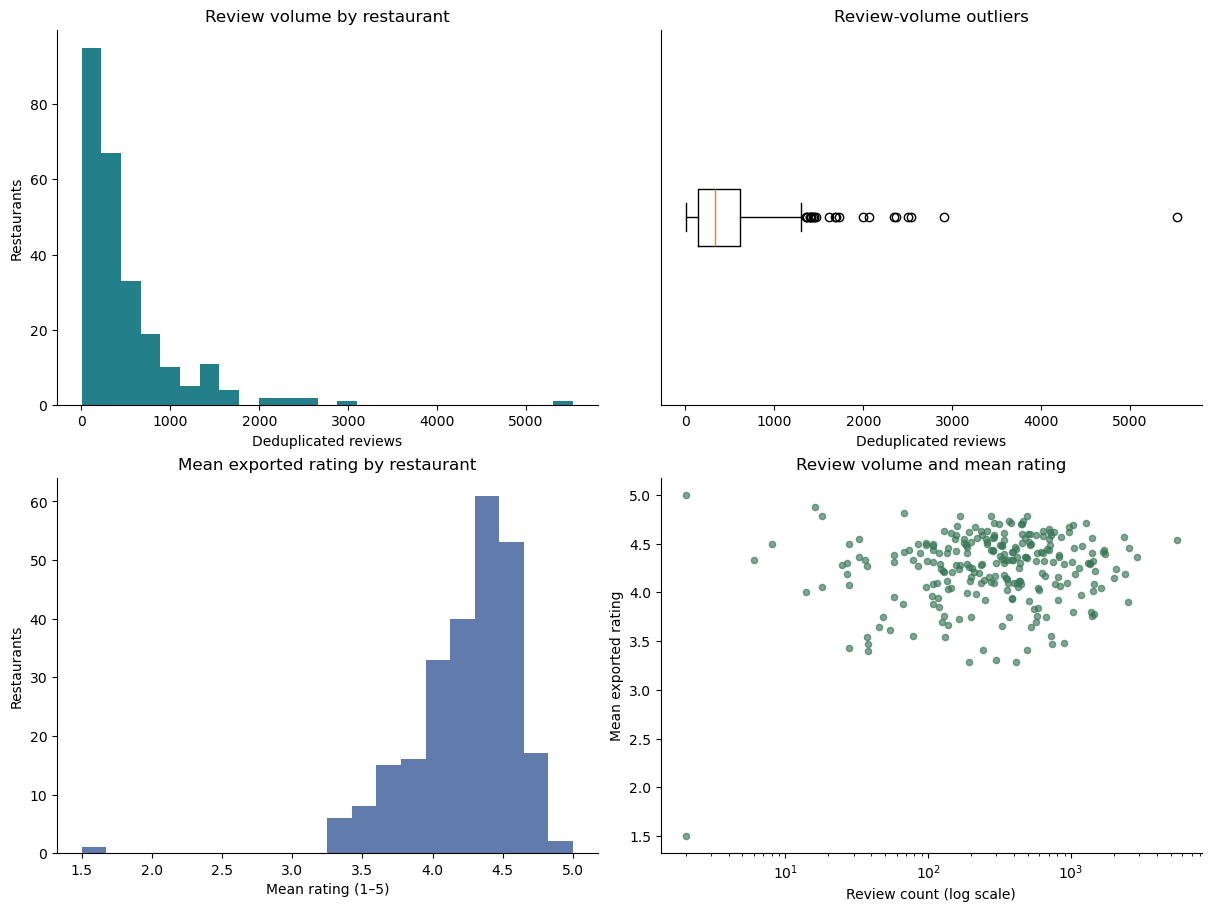

In [10]:
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(2,2,figsize=(12,9),layout='constrained')
ax[0,0].hist(restaurants['review_count'],bins=25,color='#237f89')
ax[0,0].set(title='Review volume by restaurant',xlabel='Deduplicated reviews',ylabel='Restaurants')
ax[0,1].boxplot(restaurants['review_count'].to_numpy(dtype=float),vert=False)
ax[0,1].set(title='Review-volume outliers',xlabel='Deduplicated reviews',yticks=[])
ax[1,0].hist(restaurants['mean_export_rating'],bins=20,color='#617bad')
ax[1,0].set(title='Mean exported rating by restaurant',xlabel='Mean rating (1–5)',ylabel='Restaurants')
ax[1,1].scatter(restaurants['review_count'],restaurants['mean_export_rating'],s=20,alpha=.65,color='#397758')
ax[1,1].set(xscale='log',title='Review volume and mean rating',xlabel='Review count (log scale)',ylabel='Mean exported rating')
fig.savefig(output/'restaurant_profiles.png',dpi=160)
plt.show()
plt.close(fig)

## Review ratings, dates, and available text

The year chart excludes flagged dates; boundary years are partial. Text length is displayed on a log scale to make the distribution readable.

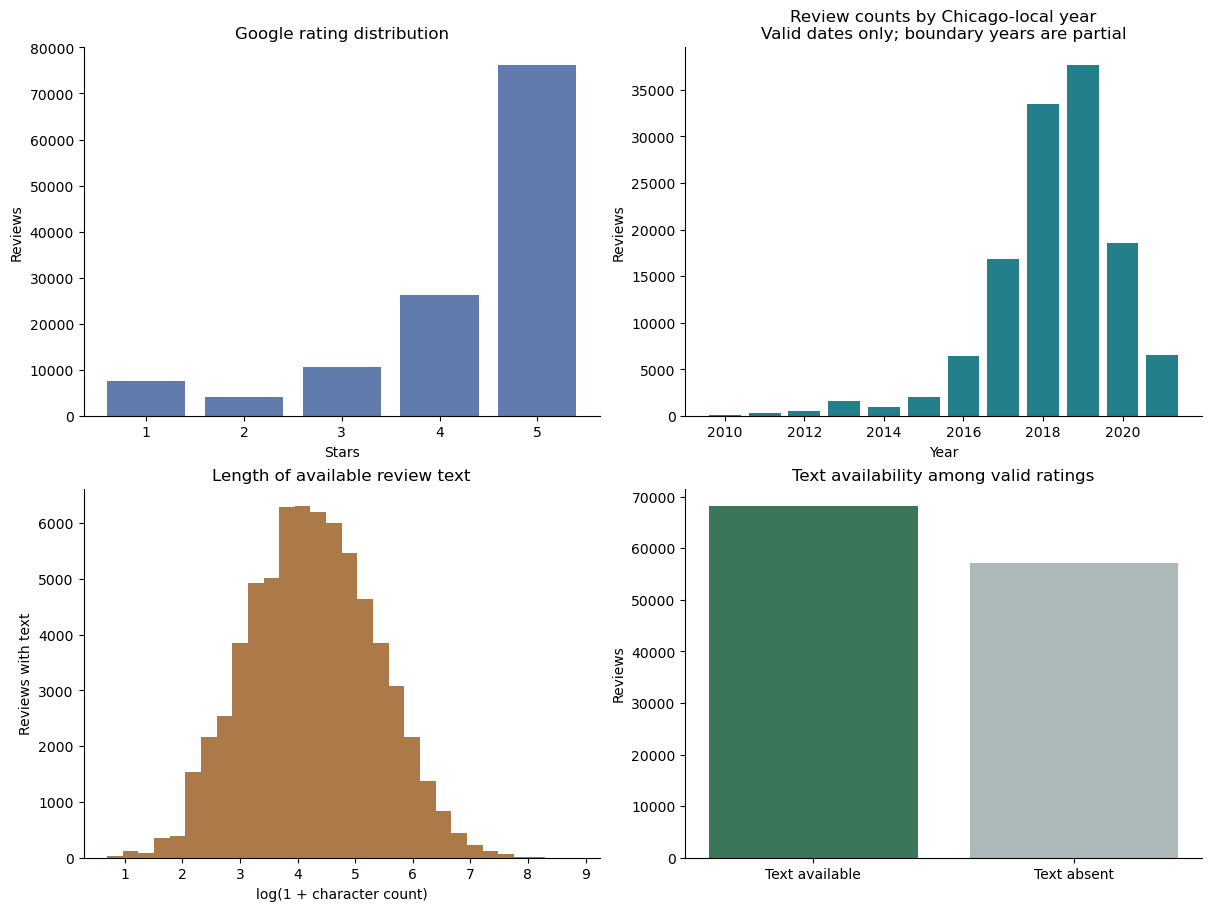

In [11]:
fig,ax=plt.subplots(2,2,figsize=(12,9),layout='constrained')
ax[0,0].bar(rating_counts.index.astype(int),rating_counts['review_count'],color='#617bad')
ax[0,0].set(title='Google rating distribution',xlabel='Stars',ylabel='Reviews',xticks=[1,2,3,4,5])
ax[0,1].bar(yearly.index,yearly['review_count'],color='#237f89')
ax[0,1].set(title='Review counts by Chicago-local year\nValid dates only; boundary years are partial',xlabel='Year',ylabel='Reviews')
# Long texts are retained; log scaling makes their distribution readable.
ax[1,0].hist(np.log1p(textual['text_character_count'].to_numpy(dtype=float)),bins=30,color='#ac7948')
ax[1,0].set(title='Length of available review text',xlabel='log(1 + character count)',ylabel='Reviews with text')
ax[1,1].bar(['Text available','Text absent'],[len(textual),len(rated)-len(textual)],color=['#397758','#adb8b8'])
ax[1,1].set(title='Text availability among valid ratings',ylabel='Reviews')
fig.savefig(output/'review_profiles.png',dpi=160)
plt.show()
plt.close(fig)

## Inspection outcomes and optional metadata

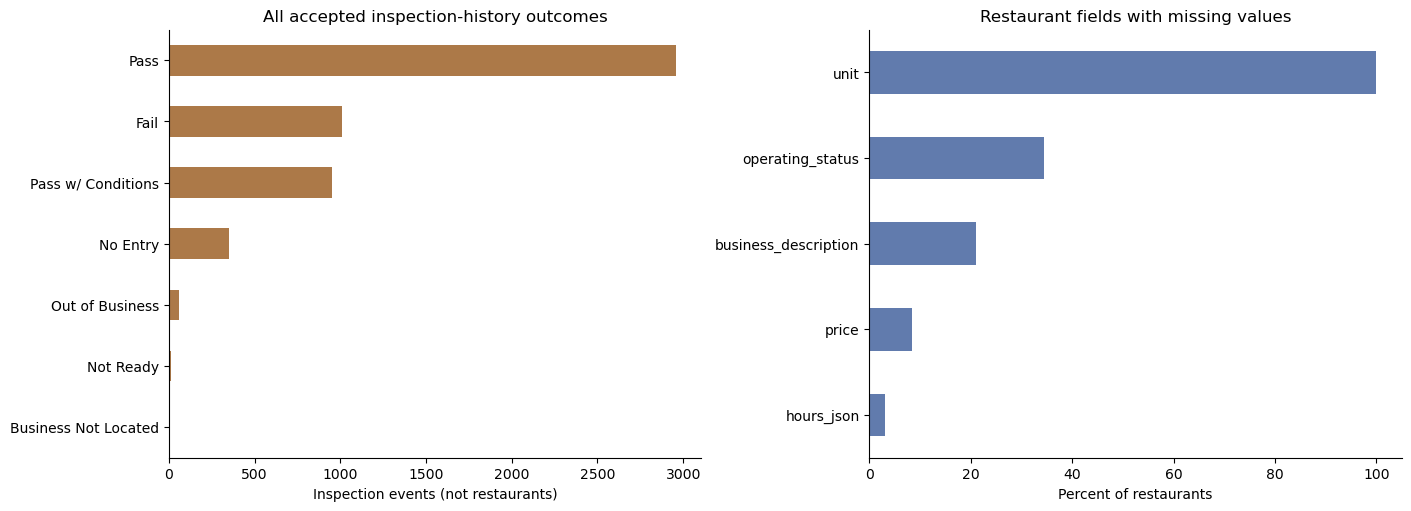

In [12]:
fig,ax=plt.subplots(1,2,figsize=(14,5),layout='constrained')
inspection_counts['event_count'].sort_values().plot.barh(ax=ax[0],color='#ac7948')
ax[0].set(title='All accepted inspection-history outcomes',xlabel='Inspection events (not restaurants)',ylabel='')
shown=restaurant_missing.loc[restaurant_missing['missing_count'].gt(0)].head(8)
if len(shown): (shown['missing_fraction']*100).sort_values().plot.barh(ax=ax[1],color='#617bad')
ax[1].set(title='Restaurant fields with missing values',xlabel='Percent of restaurants',ylabel='')
fig.savefig(output/'inspection_and_missingness_profiles.png',dpi=160)
plt.show()
plt.close(fig)

## Computed summary

In [13]:
summary={'restaurants':len(restaurants),'reviews':len(reviews),'restaurant_attributes':len(restaurants.columns),'review_attributes':len(reviews.columns),
    'inspection_events':int(restaurants['inspection_count'].sum()),'valid_date_reviews':len(dated),'flagged_date_reviews':len(rated)-len(dated),
    'reviews_with_text':len(textual),'missing_text_fraction':1-len(textual)/len(rated),'review_weighted_mean_rating':float(rated['rating'].mean()),
    'restaurant_weighted_mean_rating':float(restaurants['mean_export_rating'].mean()),'median_rating':float(rated['rating'].median()),
    'five_star_share':float(rated['rating'].eq(5).mean()),'low_rating_share':float(rated['rating'].le(2).mean()),
    'median_reviews_per_restaurant':float(restaurants['review_count'].median()),'min_reviews_per_restaurant':int(restaurants['review_count'].min()),
    'max_reviews_per_restaurant':int(restaurants['review_count'].max()),'valid_review_dates':date_range(dated['review_date_chicago']),
    'inspection_dates':[restaurants['inspection_first_date'].min().date().isoformat(),restaurants['inspection_last_date'].max().date().isoformat()],
    'primary_reviews':len(primary),'primary_restaurants':primary['restaurant_id'].nunique(),
    'primary_months':len(primary[['restaurant_id','review_month']].drop_duplicates()),
    'failure_share_among_scored_inspections':float(restaurants['inspection_fail_count'].sum()/restaurants['scored_inspection_count'].sum()),
    'validation':'passed: primary/foreign keys, counts, review flags, and strictly prior inspection dates'}
(output/'analysis_summary.json').write_text(json.dumps(summary,indent=2)+'\n',encoding='utf-8')

display(pd.Series(summary, name="value").to_frame())

,value
restaurants,252
reviews,125254
restaurant_attributes,48
review_attributes,28
inspection_events,5343
valid_date_reviews,125210
flagged_date_reviews,44
reviews_with_text,68144
missing_text_fraction,0.455954
review_weighted_mean_rating,4.270674


## Save the narrative report and interpret the results

In [14]:
report=[ANALYSIS_INTRO,'\nCOMPUTED DATASET SUMMARY\n',json.dumps(summary,indent=2),
    '\nDATA PREPARATION AND DENOMINATORS\n',
    'These final files contain the full exact-match business cohort. The review table retains flagged dates and records outside the inspection observation span, with explicit eligibility flags. Date-independent rating statistics use valid ratings, yearly statistics use valid local dates, and prior-inspection comparisons must use included_in_primary_month. Missing text is not a zero rating or neutral sentiment.',
    'Restaurant inspection counters summarize all accepted historical events. The failure share denominator includes only Pass, Pass w/ Conditions and Fail. Those histories extend beyond the review era, so their aggregates are not used here as contemporaneous rating predictors. Averages over reviews and averages over restaurants have different weights.',
    '\nNUMERIC RESTAURANT SUMMARY\n',restaurant_summary.to_string(),
    '\nRATING SUMMARY\n',review_summary.to_string(),'\nTEXT LENGTH SUMMARY (nonblank text only)\n',text_summary.to_string(),
    '\nRATING FREQUENCIES\n',rating_counts.to_string(),'\nREVIEW YEARLY PROFILE (valid dates only)\n',yearly.to_string(),
    '\nINSPECTION EVENT OUTCOMES\n',inspection_counts.to_string(),'\nPRIMARY ANALYSIS ELIGIBILITY\n',primary_status.to_string(),
    '\nRESTAURANT MISSING VALUES\n',restaurant_missing.to_string(),'\nREVIEW MISSING VALUES\n',review_missing.to_string(),
    'Missing prior_inspection_* values are structural for reviews excluded from the primary monthly analysis. Blank unit fields mean no unit was supplied. Empty optional metadata is not imputed. A parseable pre-2010 timestamp is retained but excluded from date-dependent analysis because it predates inspection coverage; it is not necessarily an erroneous timestamp.',
    '\nTEXT AVAILABILITY BY RATING (row proportions)\n',text_by_rating.to_string(),
    '\nTOP 15 CATEGORIES (multiple categories per restaurant)\n',categories.head(15).to_string(),
    '\nREVIEW-SUMMARY CORRELATIONS\n',correlations.to_string(),
    '\nINTERPRETATION\n',
    f"The review-weighted mean is {summary['review_weighted_mean_rating']:.3f}; the equal-restaurant mean is {summary['restaurant_weighted_mean_rating']:.3f}. Five-star ratings account for {summary['five_star_share']:.1%}, while ratings of 1 or 2 account for {summary['low_rating_share']:.1%}.",
    f"The median restaurant has {summary['median_reviews_per_restaurant']:.0f} reviews, compared with a maximum of {summary['max_reviews_per_restaurant']:,}. Review-level estimates give heavily reviewed restaurants more influence; the histogram and boxplot show that imbalance.",
    f"Text is unavailable for {summary['missing_text_fraction']:.1%} of valid rating records. A text or sentiment analysis therefore describes a smaller, potentially different subset. The script describes text length only and does not infer sentiment.",
    f"There are {summary['flagged_date_reviews']:,} retained records with dates excluded from temporal analysis. The yearly chart uses only valid dates, and the first/last observed years are not complete observation periods. The data do not establish activity in months without reviews.",
    'The final 252 businesses are a conservative subset of 8,317 Google Chicago restaurant candidates. Exact-match selection favors stable names, addresses, licenses and complete location evidence. Whole-history verification uses later observations; this is a retrospective cohort rather than a prospective prediction sample.',
    'Outcome counts are event-level, not the percentage of restaurants that are unsafe. Inspection types, repeated visits, changing rules and unequal follow-up affect comparisons. Correlations in the review-summary table are descriptive and do not demonstrate causality or significance. All source/collection details and column definitions are in dataset_description.txt.',
    '\nDATA TYPES AND NONNULL COUNTS\n',info.getvalue(),
    '\nGENERATED FIGURES\n','restaurant_profiles.png; review_profiles.png; inspection_and_missingness_profiles.png.',
    '\nMETHOD TRACEABILITY\n','The notebook paths and cell indices are documented in the script header and dataset_description.txt. Summary tables use describe, isna, value_counts, groupby/agg, crosstab and corr; visualizations use histograms, boxplots, scatterplots and frequency bars.']
(output/'descriptive_analysis_report.txt').write_text('\n\n'.join(report)+'\n',encoding='utf-8')
print(json.dumps(summary,indent=2))
print('Saved report, tables, and figures to',output)

interpretation_start = report.index("\nINTERPRETATION\n") + 1
interpretation_end = report.index("\nDATA TYPES AND NONNULL COUNTS\n")
display(Markdown("\n\n".join(report[interpretation_start:interpretation_end])))

{
  "restaurants": 252,
  "reviews": 125254,
  "restaurant_attributes": 48,
  "review_attributes": 28,
  "inspection_events": 5343,
  "valid_date_reviews": 125210,
  "flagged_date_reviews": 44,
  "reviews_with_text": 68144,
  "missing_text_fraction": 0.45595350248295463,
  "review_weighted_mean_rating": 4.270673990451403,
  "restaurant_weighted_mean_rating": 4.242264173257724,
  "median_rating": 5.0,
  "five_star_share": 0.6087310584891501,
  "low_rating_share": 0.09539016718028966,
  "median_reviews_per_restaurant": 327.0,
  "min_reviews_per_restaurant": 2,
  "max_reviews_per_restaurant": 5529,
  "valid_review_dates": [
    "2010-01-05",
    "2021-08-28"
  ],
  "inspection_dates": [
    "2010-01-04",
    "2026-10-29"
  ],
  "primary_reviews": 103049,
  "primary_restaurants": 249,
  "primary_months": 13271,
  "failure_share_among_scored_inspections": 0.20548780487804877,
  "validation": "passed: primary/foreign keys, counts, review flags, and strictly prior inspection dates"
}
Saved re

The review-weighted mean is 4.271; the equal-restaurant mean is 4.242. Five-star ratings account for 60.9%, while ratings of 1 or 2 account for 9.5%.

The median restaurant has 327 reviews, compared with a maximum of 5,529. Review-level estimates give heavily reviewed restaurants more influence; the histogram and boxplot show that imbalance.

Text is unavailable for 45.6% of valid rating records. A text or sentiment analysis therefore describes a smaller, potentially different subset. The script describes text length only and does not infer sentiment.

There are 44 retained records with dates excluded from temporal analysis. The yearly chart uses only valid dates, and the first/last observed years are not complete observation periods. The data do not establish activity in months without reviews.

The final 252 businesses are a conservative subset of 8,317 Google Chicago restaurant candidates. Exact-match selection favors stable names, addresses, licenses and complete location evidence. Whole-history verification uses later observations; this is a retrospective cohort rather than a prospective prediction sample.

Outcome counts are event-level, not the percentage of restaurants that are unsafe. Inspection types, repeated visits, changing rules and unequal follow-up affect comparisons. Correlations in the review-summary table are descriptive and do not demonstrate causality or significance. All source/collection details and column definitions are in dataset_description.txt.

## Interpretation limits

The accepted restaurants form a small retrospective subset, not a Chicago census or random sample. Exact matching favors stable names, addresses, licenses, and complete location evidence. Whole-history screening can select businesses using later observations. Reviews are self-selected, missing text limits text analysis, and inspection types and procedures differ over time. No causal effects or predictive performance are established here.